<a href="https://colab.research.google.com/github/tKaiB/Capstone_Chicago/blob/main/notebooks/Cap_Chicago_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Initializing data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/Capstone/cleaned_data.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
df

,Date,Crime_Type_ID,Location_Type_ID,Arrest,Domestic,Beat,District,Ward,Community Area,Latitude,Longitude,Year,Time_Of_Day,Day_of_Week,Holiday,Seasons,Primary Type,Location Description,Crime_Category
0,2020-01-01 00:00:00,1,1,False,False,1434,14,32,22,41.915306,-87.686639,2020,1,Wednesday,1,Winter,DECEPTIVE PRACTICE,APARTMENT,Property
1,2020-01-01 00:00:00,2,2,False,True,413,4,8,47,41.728192,-87.600985,2020,1,Wednesday,1,Winter,OFFENSE INVOLVING CHILDREN,RESIDENCE,Violent
2,2020-01-01 00:00:00,3,1,False,False,814,8,22,56,41.812274,-87.748177,2020,1,Wednesday,1,Winter,CRIMINAL SEXUAL ASSAULT,APARTMENT,Violent
3,2020-01-01 00:00:00,1,1,False,False,1922,19,47,6,41.940222,-87.669039,2020,1,Wednesday,1,Winter,DECEPTIVE PRACTICE,APARTMENT,Property
4,2020-01-01 00:00:00,4,2,False,False,831,8,18,66,41.762067,-87.699077,2020,1,Wednesday,1,Winter,DECEPTIVE PRACTICE,RESIDENCE,Property
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
627158,2022-12-07 23:50:00,64,124,False,False,813,8,23,65,41.785931,-87.723266,2022,4,Wednesday,0,Winter,THEFT,TAVERN / LIQUOR STORE,Property
627159,2022-12-07 23:51:00,312,1,False,True,221,2,4,39,41.814564,-87.604481,2022,4,Wednesday,0,Winter,BATTERY,APARTMENT,Violent
627160,2022-12-07 23:52:00,11,11,False,True,1112,11,27,23,41.897901,-87.718833,2022,4,Wednesday,0,Winter,BATTERY,STREET,Violent
627161,2022-12-07 23:58:00,221,11,True,False,734,7,6,67,41.761362,-87.657710,2022,4,Wednesday,0,Winter,NARCOTICS,STREET,Other


In [3]:
df.dtypes

,0
Date,object
Crime_Type_ID,int64
Location_Type_ID,int64
Arrest,bool
Domestic,bool
Beat,int64
District,int64
Ward,int64
Community Area,int64
Latitude,float64


In [4]:
df['Date'] = pd.to_datetime(df['Date'])
df['Day_of_Week'] = df['Date'].dt.dayofweek
df['Month']= df['Date'].dt.month
df['Year']= df['Date'].dt.year
df['IsWeekend']= df['Day_of_Week'].isin([5, 6]).astype(int)
df.dtypes

,0
Date,datetime64[ns]
Crime_Type_ID,int64
Location_Type_ID,int64
Arrest,bool
Domestic,bool
Beat,int64
District,int64
Ward,int64
Community Area,int64
Latitude,float64


In [5]:
df

,Date,Crime_Type_ID,Location_Type_ID,Arrest,Domestic,Beat,District,Ward,Community Area,Latitude,...,Year,Time_Of_Day,Day_of_Week,Holiday,Seasons,Primary Type,Location Description,Crime_Category,Month,IsWeekend
0,2020-01-01 00:00:00,1,1,False,False,1434,14,32,22,41.915306,...,2020,1,2,1,Winter,DECEPTIVE PRACTICE,APARTMENT,Property,1,0
1,2020-01-01 00:00:00,2,2,False,True,413,4,8,47,41.728192,...,2020,1,2,1,Winter,OFFENSE INVOLVING CHILDREN,RESIDENCE,Violent,1,0
2,2020-01-01 00:00:00,3,1,False,False,814,8,22,56,41.812274,...,2020,1,2,1,Winter,CRIMINAL SEXUAL ASSAULT,APARTMENT,Violent,1,0
3,2020-01-01 00:00:00,1,1,False,False,1922,19,47,6,41.940222,...,2020,1,2,1,Winter,DECEPTIVE PRACTICE,APARTMENT,Property,1,0
4,2020-01-01 00:00:00,4,2,False,False,831,8,18,66,41.762067,...,2020,1,2,1,Winter,DECEPTIVE PRACTICE,RESIDENCE,Property,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
627158,2022-12-07 23:50:00,64,124,False,False,813,8,23,65,41.785931,...,2022,4,2,0,Winter,THEFT,TAVERN / LIQUOR STORE,Property,12,0
627159,2022-12-07 23:51:00,312,1,False,True,221,2,4,39,41.814564,...,2022,4,2,0,Winter,BATTERY,APARTMENT,Violent,12,0
627160,2022-12-07 23:52:00,11,11,False,True,1112,11,27,23,41.897901,...,2022,4,2,0,Winter,BATTERY,STREET,Violent,12,0
627161,2022-12-07 23:58:00,221,11,True,False,734,7,6,67,41.761362,...,2022,4,2,0,Winter,NARCOTICS,STREET,Other,12,0


## Importing libraries and dependencies

In [6]:
# dependency
!pip install imbalanced-learn xgboost --quiet

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from imblearn.over_sampling import SMOTE
import warnings
warnings.filterwarnings('ignore')

## More Data Tweakings

In [8]:
df['Arrest']   = df['Arrest'].astype(int)
df['Domestic'] = df['Domestic'].astype(int)

# adding a pandemic flag
df['Lockdown_Period'] = ((df['Year'] == 2020) & (df['Month'].between(3, 6))).astype(int)

def pandemic_phase(row):
    if row['Year'] == 2020 and row['Month'] in [3, 4, 5, 6]:
        return 'acute_lockdown'
    elif row['Year'] == 2020 and row['Month'] in [7, 8, 9]:
        return 'reopening'
    elif row['Year'] == 2020 and row['Month'] in [10, 11, 12]:
        return 'second_wave'
    elif row['Year'] == 2020 and row['Month'] in [1, 2]:
        return 'before_lockdown'
    else:
        return 'post_lockdown'

df['Pandemic_Phase'] = df.apply(pandemic_phase, axis=1)
df = pd.get_dummies(df, columns=['Pandemic_Phase'], drop_first=True)

# drop columns already encoded by IDs
df.drop(columns=['Primary Type', 'Location Description', 'Date'], inplace=True)

# One-hot encode "Seasons" and "Crime_Category"
df = pd.get_dummies(df, columns=['Seasons', 'Crime_Category'], drop_first=True)

#    Drop District and Ward to reduce multicollinearity
df.drop(columns=['District', 'Ward'], inplace=True)

# make holiday columns more meaning
def group_holiday(val):
    if val == 0:
        return 'non_holiday'
    elif val in [13, 14, 17, 1, 18]:   # Thanksgiving, Christmas, New Year's
        return 'major_holiday'
    elif val in [7, 8, 6, 9]:          # Independence Day, Memorial Day, Labor Day
        return 'summer_holiday'
    else:                               # All other holidays
        return 'minor_holiday'

df['Holiday_Group'] = df['Holiday'].apply(group_holiday)
df = pd.get_dummies(df, columns=['Holiday_Group'], drop_first=True)
df.drop(columns=['Holiday'], inplace=True)

print(f"Shape: {df.shape}")
print(f"\nNull values:\n{df.isnull().sum()[df.isnull().sum() > 0]}")
print(f"\nData types:\n{df.dtypes}")
print(f"\nArrest distribution:\n{df['Arrest'].value_counts(normalize=True).round(3)}")

Shape: (627163, 26)

Null values:
Series([], dtype: int64)

Data types:
Crime_Type_ID                       int64
Location_Type_ID                    int64
Arrest                              int64
Domestic                            int64
Beat                                int64
Community Area                      int64
Latitude                          float64
Longitude                         float64
Year                                int32
Time_Of_Day                         int64
Day_of_Week                         int32
Month                               int32
IsWeekend                           int64
Lockdown_Period                     int64
Pandemic_Phase_before_lockdown       bool
Pandemic_Phase_post_lockdown         bool
Pandemic_Phase_reopening             bool
Pandemic_Phase_second_wave           bool
Seasons_Spring                       bool
Seasons_Summer                       bool
Seasons_Winter                       bool
Crime_Category_Property              bool
Crim

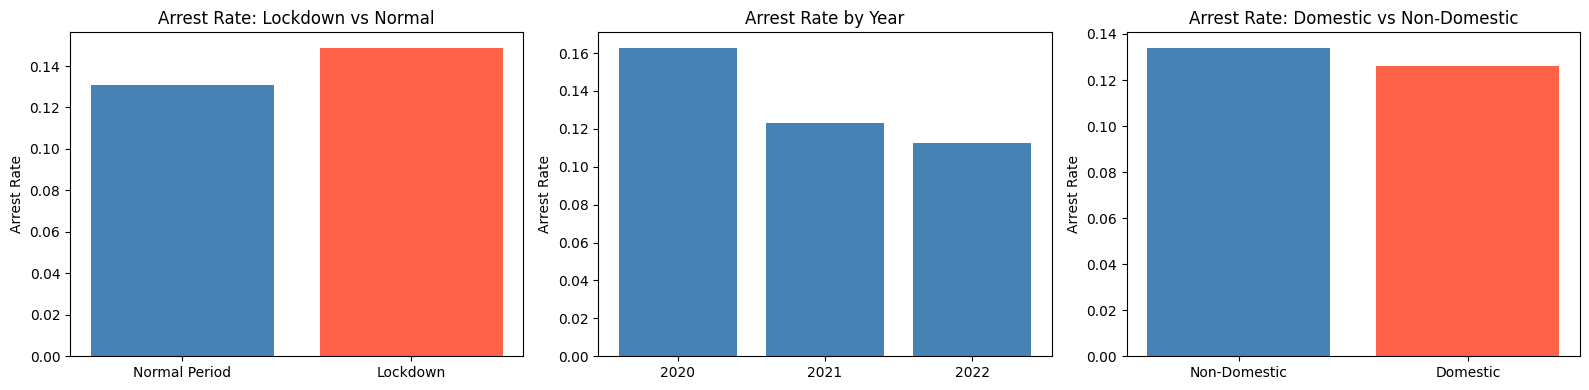

In [9]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Arrest rate by Pandemic Phase
phase_cols = [c for c in df.columns if 'Pandemic_Phase' in c]
phase_arrest = df.groupby(phase_cols[0])['Arrest'].mean() if phase_cols else None

# Arrest rate by Lockdown Period
lockdown_arrest = df.groupby('Lockdown_Period')['Arrest'].mean()
axes[0].bar(['Normal Period', 'Lockdown'], lockdown_arrest.values, color=['steelblue', 'tomato'])
axes[0].set_title('Arrest Rate: Lockdown vs Normal')
axes[0].set_ylabel('Arrest Rate')

# Arrest rate by Year
year_arrest = df.groupby('Year')['Arrest'].mean()
axes[1].bar(year_arrest.index.astype(str), year_arrest.values, color='steelblue')
axes[1].set_title('Arrest Rate by Year')
axes[1].set_ylabel('Arrest Rate')

# Arrest rate by Domestic
domestic_arrest = df.groupby('Domestic')['Arrest'].mean()
axes[2].bar(['Non-Domestic', 'Domestic'], domestic_arrest.values, color=['steelblue', 'tomato'])
axes[2].set_title('Arrest Rate: Domestic vs Non-Domestic')
axes[2].set_ylabel('Arrest Rate')

plt.tight_layout()
plt.show()

In [10]:
# null checks
null_cols = df.isnull().sum()
null_cols = null_cols[null_cols > 0]

if len(null_cols) == 0:
    print("No nulls found — good to go.")
else:
    print(f"Columns with nulls:\n{null_cols}")

    # For numeric columns: fill with median (robust to outliers)
    for col in null_cols.index:
        if df[col].dtype in ['float64', 'int64']:
            df[col].fillna(df[col].median(), inplace=True)
            print(f"  Filled '{col}' nulls with median: {df[col].median()}")

    # Re-check
    print(f"\nNulls remaining: {df.isnull().sum().sum()}")

No nulls found — good to go.


In [11]:
# Check for highly correlated features (threshold > 0.90)
corr_matrix = df.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr = [(col, row, upper.loc[row, col])
             for col in upper.columns
             for row in upper.index
             if upper.loc[row, col] > 0.90]

if high_corr:
    print("Highly correlated feature pairs (> 0.90):")
    for col, row, val in sorted(high_corr, key=lambda x: -x[2]):
        print(f"  {col} <-> {row}: {val:.3f}")

    # Drop the second of each highly correlated pair
    cols_to_drop = list(set([pair[1] for pair in high_corr]))
    print(f"\nDropping: {cols_to_drop}")
    df.drop(columns=cols_to_drop, inplace=True)
else:
    print("No highly correlated features found — no action needed.")

No highly correlated features found — no action needed.


In [12]:
# pre-modelling
print("=" * 50)
print("FINAL DATASET SUMMARY")
print("=" * 50)
print(f"Total records   : {len(df):,}")
print(f"Total features  : {df.shape[1] - 1}")  # exclude target
print(f"Target          : Arrest")
print(f"Arrest = 1      : {df['Arrest'].sum():,} ({df['Arrest'].mean()*100:.1f}%)")
print(f"Arrest = 0      : {(df['Arrest']==0).sum():,} ({(1-df['Arrest'].mean())*100:.1f}%)")
print(f"\nLockdown records: {df['Lockdown_Period'].sum():,}")
print(f"Year breakdown  :\n{df['Year'].value_counts().sort_index()}")
print(f"\nAll columns:\n{list(df.columns)}")

FINAL DATASET SUMMARY
Total records   : 627,163
Total features  : 25
Target          : Arrest
Arrest = 1      : 83,091 (13.2%)
Arrest = 0      : 544,072 (86.8%)

Lockdown records: 63,685
Year breakdown  :
Year
2020    206923
2021    201742
2022    218498
Name: count, dtype: int64

All columns:
['Crime_Type_ID', 'Location_Type_ID', 'Arrest', 'Domestic', 'Beat', 'Community Area', 'Latitude', 'Longitude', 'Year', 'Time_Of_Day', 'Day_of_Week', 'Month', 'IsWeekend', 'Lockdown_Period', 'Pandemic_Phase_before_lockdown', 'Pandemic_Phase_post_lockdown', 'Pandemic_Phase_reopening', 'Pandemic_Phase_second_wave', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Crime_Category_Property', 'Crime_Category_Violent', 'Holiday_Group_minor_holiday', 'Holiday_Group_non_holiday', 'Holiday_Group_summer_holiday']


## Modelling

In [13]:
# Getting the X and Y values
TARGET = 'Arrest'

X = df.drop(columns=[TARGET])
y = df[TARGET]


# Removing Crime_Category (one-hot) from columns
cat_cols = [c for c in X.columns if 'Crime_Category' in c]
X_id = X.drop(columns=cat_cols)

print(f"Features: {X.shape[1]}")
print(f"\nFeature names:\n{list(X.columns)}")
print(f"Class balance:\n{y.value_counts()}")
print(f"Class balance (%):\n{y.value_counts(normalize=True).mul(100).round(1)}")

Features: 25

Feature names:
['Crime_Type_ID', 'Location_Type_ID', 'Domestic', 'Beat', 'Community Area', 'Latitude', 'Longitude', 'Year', 'Time_Of_Day', 'Day_of_Week', 'Month', 'IsWeekend', 'Lockdown_Period', 'Pandemic_Phase_before_lockdown', 'Pandemic_Phase_post_lockdown', 'Pandemic_Phase_reopening', 'Pandemic_Phase_second_wave', 'Seasons_Spring', 'Seasons_Summer', 'Seasons_Winter', 'Crime_Category_Property', 'Crime_Category_Violent', 'Holiday_Group_minor_holiday', 'Holiday_Group_non_holiday', 'Holiday_Group_summer_holiday']
Class balance:
Arrest
0    544072
1     83091
Name: count, dtype: int64
Class balance (%):
Arrest
0    86.8
1    13.2
Name: proportion, dtype: float64


In [14]:
sm = SMOTE(random_state=42)

X_res_id, y_res_id = sm.fit_resample(X_id, y)
print(f"After SMOTE — X: {X_res_id.shape}, y distribution:\n{pd.Series(y_res_id).value_counts()}")


After SMOTE — X: (1088144, 23), y distribution:
Arrest
0    544072
1    544072
Name: count, dtype: int64


In [15]:
X_train_id, X_test_id, y_train_id, y_test_id = train_test_split(
    X_res_id, y_res_id, test_size=0.2, random_state=42, stratify=y_res_id
)
print(f"Train: {X_train_id.shape} | Test: {X_test_id.shape}")

Train: (870515, 23) | Test: (217629, 23)


### Logistic Regression

In [20]:


# Logistic Regression needs scaling unlike tree-based models
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_id)
X_test_scaled  = scaler.transform(X_test_id)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train_id)

lr_train = roc_auc_score(y_train_id, lr.predict_proba(X_train_scaled)[:,1])
lr_test  = roc_auc_score(y_test_id,  lr.predict_proba(X_test_scaled)[:,1])

print(f"Logistic Regression — Train: {lr_train:.4f} | Test: {lr_test:.4f}")

Logistic Regression — Train: 0.8783 | Test: 0.8771


### Random Forest Classifier

In [16]:
rf_id = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_id.fit(X_train_id, y_train_id)
y_pred_id = rf_id.predict(X_test_id)
y_prob_id = rf_id.predict_proba(X_test_id)[:, 1]

print("=== Random Forest Results With Crime_ID ===")
print(classification_report(y_test_id, y_pred_id, target_names=['No Arrest', 'Arrest']))

rfc_train = roc_auc_score(y_train_id, rf_id.predict_proba(X_train_id)[:,1])
rfc_test  = roc_auc_score(y_test_id,  rf_id.predict_proba(X_test_id)[:,1])
print(f"Train ROC-AUC : {rfc_train:.4f}")
print(f"Test ROC-AUC  : {rfc_test:.4f}")

print(f"ROC-AUC Score: {roc_auc_score(y_test_id, y_prob_id):.4f}")

=== Random Forest Results With Crime_ID ===
              precision    recall  f1-score   support

   No Arrest       0.84      0.92      0.88    108815
      Arrest       0.91      0.82      0.87    108814

    accuracy                           0.87    217629
   macro avg       0.88      0.87      0.87    217629
weighted avg       0.88      0.87      0.87    217629

Train ROC-AUC : 0.9522
Test ROC-AUC  : 0.9458
ROC-AUC Score: 0.9458


### XGBoost

In [19]:
xgb = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    use_label_encoder=False,
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)
xgb.fit(X_train_id, y_train_id)
y_pred_id_xgb = xgb.predict(X_test_id)
y_prob_id_xgb = xgb.predict_proba(X_test_id)[:, 1]

print("=== XGBoost Results ===")
print(classification_report(y_test_id, y_pred_id_xgb, target_names=['No Arrest', 'Arrest']))

xgb_train = roc_auc_score(y_train_id, xgb.predict_proba(X_train_id)[:,1])
xgb_test  = roc_auc_score(y_test_id,  xgb.predict_proba(X_test_id)[:,1])
print(f"XGBoost — Train: {xgb_train:.4f} | Test: {xgb_test:.4f}")

print(f"ROC-AUC Score: {roc_auc_score(y_test_id, y_prob_id_xgb):.4f}")

=== XGBoost Results ===
              precision    recall  f1-score   support

   No Arrest       0.85      0.94      0.89    108815
      Arrest       0.93      0.84      0.88    108814

    accuracy                           0.89    217629
   macro avg       0.89      0.89      0.89    217629
weighted avg       0.89      0.89      0.89    217629

XGBoost — Train: 0.9548 | Test: 0.9537
ROC-AUC Score: 0.9537


## Comparing Models

In [21]:
results = {
    'Logistic Regression' : (lr_train,  lr_test),
    'Random Forest'       : (rfc_train, rfc_test),
    'XGBoost'             : (xgb_train, xgb_test)
}

print(f"\n{'Model':<25} {'Train AUC':>10} {'Test AUC':>10} {'Gap':>8}")
print("-" * 55)
for model, (train, test) in results.items():
    gap = train - test
    flag = '⚠️' if gap > 0.05 else '✅'
    print(f"{model:<25} {train:>10.4f} {test:>10.4f} {gap:>7.4f} {flag}")


Model                      Train AUC   Test AUC      Gap
-------------------------------------------------------
Logistic Regression           0.8783     0.8771  0.0012 ✅
Random Forest                 0.9522     0.9458  0.0064 ✅
XGBoost                       0.9548     0.9537  0.0011 ✅


### Using Crime_Category for comparison

In [22]:
# TARGET = 'Arrest'

# X = df.drop(columns=[TARGET])
# y = df[TARGET]

# print(f"Features: {X.shape[1]}")
# print(f"\nFeature names:\n{list(X.columns)}")
# print(f"Class balance:\n{y.value_counts()}")
# print(f"Class balance (%):\n{y.value_counts(normalize=True).mul(100).round(1)}")

# X_cat = X.drop(columns=['Crime_Type_ID'])

In [23]:
# sm = SMOTE(random_state=42)

# X_res_cat, y_res_cat = sm.fit_resample(X_cat, y)

# print(f"After SMOTE — X: {X_res_cat.shape}, y distribution:\n{pd.Series(y_res_cat).value_counts()}")


In [24]:

# X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
#     X_res_cat, y_res_cat, test_size=0.2, random_state=42, stratify=y_res_cat
# )
# print(f"With Cat")
# print(f"Train: {X_train_cat.shape} | Test: {X_test_cat.shape}")

In [25]:
# rf_cat = RandomForestClassifier(
#     n_estimators=100,
#     max_depth=15,
#     min_samples_leaf=5,
#     random_state=42,
#     n_jobs=-1
# )


# rf_cat.fit(X_train_cat, y_train_cat)
# y_pred_cat = rf_cat.predict(X_test_cat)
# y_prob_cat = rf_cat.predict_proba(X_test_cat)[:, 1]

# print("=== Random Forest Results With Category ===")
# print(classification_report(y_test_cat, y_pred_cat, target_names=['No Arrest', 'Arrest']))
# print(f"ROC-AUC Score: {roc_auc_score(y_test_cat, y_prob_cat):.4f}")


In [26]:
# cm = confusion_matrix(y_test_cat, y_pred_cat)
# plt.figure(figsize=(6, 4))
# sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
#             xticklabels=['No Arrest', 'Arrest'],
#             yticklabels=['No Arrest', 'Arrest'])
# plt.title('Confusion Matrix — Random Forest')
# plt.ylabel('Actual')
# plt.xlabel('Predicted')
# plt.tight_layout()
# plt.show()

In [27]:
# importances = pd.Series(rf_cat.feature_importances_, index=X_cat.columns)
# top15 = importances.nlargest(15)

# plt.figure(figsize=(10, 6))
# top15.sort_values().plot(kind='barh', color='steelblue')
# plt.title('Top 15 Features — Arrest Prediction')
# plt.xlabel('Importance Score')
# plt.tight_layout()
# plt.show()